**Etapa 1 – Carregar os dados**

In [2]:
from google.colab import files
uploaded = files.upload()

Saving base_credito.csv to base_credito.csv


In [3]:
import pandas as pd

tabela = pd.read_csv("base_credito.csv")
tabela.head()

,idade,renda_mensal,score_credito,historico_pagamentos,valor_emprestimo
0,47,11522.48,634,76.73,35229.74
1,40,13157.86,589,90.83,44177.99
2,38,7296.76,721,77.94,33868.30
3,42,11193.87,710,94.09,52289.28
4,43,12798.60,576,73.83,38663.54


In [4]:
import pandas as pd

tabela = pd.read_csv("base_credito.csv")
tabela.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   idade                 50000 non-null  int64  
 1   renda_mensal          50000 non-null  float64
 2   score_credito         50000 non-null  int64  
 3   historico_pagamentos  50000 non-null  float64
 4   valor_emprestimo      50000 non-null  float64
dtypes: float64(3), int64(2)
memory usage: 1.9 MB


**Etapa 2 – Conhecer os dados**

1.Quais são as variáveis utilizadas como entrada.
*   idade;
*   renda_mensal;
*   score_credito;
*   historico_pagamentos.

2.Qual é a variável que deverá ser prevista.
*   Valor do empréstimo disponível.

3.Quais tipos de dados estão presentes na base.
*   Idade: int;
*   Renda_mensal: float;
*   Score_credito: int;
*   Historico_pagamentos: float;
*   Valor_emprestimo: float.

4.Explique brevemente o significado de cada variável.
*   Idade: idade do cliente;
*   Renda_mensal: renda mensal do cliente;
*   Score_credito: score de credito do cliente, medido por baixo e alto para saber se o perfil se encaixa para emprestimos, cartões, compras de grande valor e etc;
*   Historico_pagamentos: percentual de pagamentos realizados em dia pelo cliente de 0% a 100%;
*   Valor_emprestimo: valor disponivel para emrpestimo do cliente.
    


**Etapa 3 – Analisar os dados**

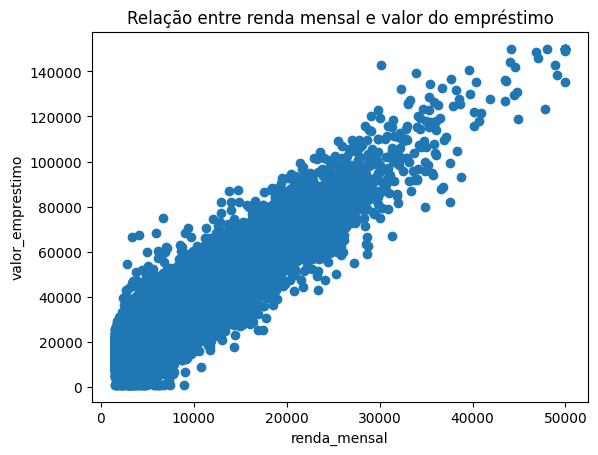

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

tabela = pd.read_csv("base_credito.csv")
tabela.head()
plt.scatter(tabela["renda_mensal"], tabela["valor_emprestimo"])
plt.xlabel("renda_mensal")
plt.ylabel("valor_emprestimo")
plt.title("Relação entre renda mensal e valor do empréstimo")
plt.show()

O gráfico mostra uma correlação forte e positiva entre renda mensal e valor do empréstimo: conforme a renda aumenta, o valor do empréstimo também tende a aumentar, de forma bastante consistente.

**Etapa 4 – Preparar os dados**

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split

tabela = pd.read_csv("base_credito.csv")
tabela.head()
X = tabela[["idade", "renda_mensal", "score_credito", "historico_pagamentos"]]
y = tabela["valor_emprestimo"]
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42)
print(len(X_treino))
print(len(X_teste))

40000
10000


**Etapa 5 – Treinar o modelo**

In [7]:
from sklearn.linear_model import LinearRegression

modelo = LinearRegression()
modelo.fit(X_treino, y_treino)

LinearRegression()

In [8]:
previsoes = modelo.predict(X_teste)
print(previsoes[:5])

[14806.33565684 29512.49287915 25840.73554724 21077.52290488
 27919.31404641]


**Etapa 6 – Avaliar o modelo**

In [9]:
from sklearn.metrics import mean_absolute_error, r2_score

mae = mean_absolute_error(y_teste, previsoes)
r2 = r2_score(y_teste, previsoes)

print("MAE:", mae)
print("R²:", r2)
y_teste.describe()

MAE: 2985.9449770383862
R²: 0.9223268951278678


,valor_emprestimo
count,10000.000000
mean,31767.055778
std,14403.959495
min,1000.000000
25%,22030.112500
50%,29201.530000
75%,38201.072500
max,150000.000000


Para avaliar o modelo, utilizamos as métricas MAE e R². O MAE indica que, em média, o modelo erra o valor previsto do empréstimo em aproximadamente R$ 2.985,94, para mais ou para menos. Já o R² deu uma nota de 0.92, numa escala de 0 a 1, o que indica que o modelo consegue explicar cerca de 92% da variação nos valores dos empréstimos, um desempenho considerado bom.

**Etapa 7 – Comparar valores reais e previstos**

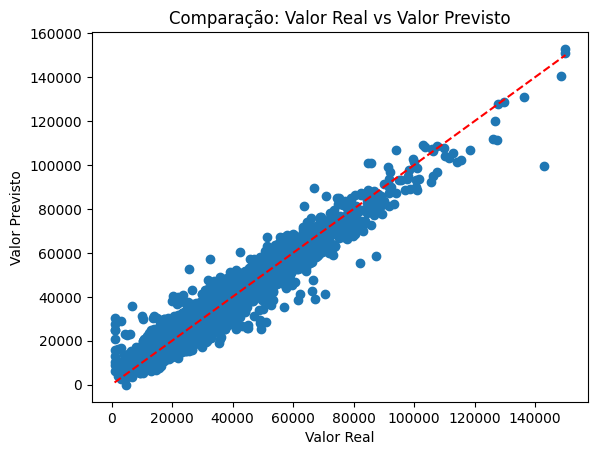

In [10]:
import matplotlib.pyplot as plt

plt.scatter(y_teste, previsoes)
plt.plot([y_teste.min(), y_teste.max()], [y_teste.min(), y_teste.max()], color="red", linestyle="--")
plt.xlabel("Valor Real")
plt.ylabel("Valor Previsto")
plt.title("Comparação: Valor Real vs Valor Previsto")
plt.show()

Na representação gráfica temos uma linha vermelha que representa onde os pontos estariam se a previsão fosse perfeita. Podemos notar que os pontos azuis estão bem próximos da linha vermelha, especialmente na parte de baixo e no meio do gráfico, o que confirma visualmente o R2 alto. Notamos também que os pontos se afastam da linha vermelha nos empréstimos acima de 100.000, isso pode acontecer porque há menos exemplos de empréstimos nessa faixa de valor para o modelo aprender o padrão.

**Etapa 8 – Fazer uma previsão**

1. Características do cliente:
*   idade: [23];
*   renda_mensal: [3500];
*   score_credito: [700];
*   historico_pagamentos: [92].



In [11]:
novo_cliente = pd.DataFrame({
    "idade": [23],
    "renda_mensal": [3500],
    "score_credito": [700],
    "historico_pagamentos": [92]
})

previsao_novo_cliente = modelo.predict(novo_cliente)
print(previsao_novo_cliente)

[23440.98400044]


O valor previsto de 23.440,98 é coerente com o padrão identificado na análise: como a renda mensal do cliente (R$3.500) está na faixa mais baixa, é esperado um empréstimo proporcionalmente menor, já que vimos que renda e valor do empréstimo têm correlação positiva.

**Etapa 9 – Conclusão**

O modelo apresentou bons resultados: as métricas MAE e R2 indicaram um desempenho satisfatório na estimativa dos valores de empréstimo. Quanto às limitações, observou-se que o modelo tende a errar mais nas previsões de empréstimos de valores mais altos, provavelmente porque a base possui menos exemplos nessa faixa. Com uma quantidade maior de dados para empréstimos elevados, o modelo poderia realizar previsões mais precisas nesse intervalo.